# Siparişler - `review_score` Çok Değişkenli Regresyonu

In [1]:
%load_ext autoreload
%autoreload 2

In [6]:
%pip install statsmodels

   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---- ----------------------------------- 1.3/11.4 MB 13.2 MB/s eta 0:00:01
   ------------------- -------------------- 5.5/11.4 MB 20.5 MB/s eta 0:00:01
   ------------------------------ --------- 8.7/11.4 MB 17.7 MB/s eta 0:00:01
   ---------------------------------------  11.3/11.4 MB 16.4 MB/s eta 0:00:01
   ---------------------------------------- 11.4/11.4 MB 15.9 MB/s  0:00:00

   ---------------------------------------- 0/5 [wrapt]
   -------- ------------------------------- 1/5 [patsy]
   -------- ------------------------------- 1/5 [patsy]
   ---------------- ----------------------- 2/5 [interface-meta]
   ------------------------ --------------- 3/5 [formulaic]
   ------------------------ --------------- 3/5 [formulaic]
   ------------------------ --------------- 3/5 [formulaic]
   ------------------------ --------------- 3/5 [formulaic]
   -------------------------------- ------- 4/5 [statsmodels]
   --


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

sns.set_theme(style="whitegrid")

⚠️ Devam etmeden önce:
* 💾 Önceki ünitenin Siparişler çözümünü indirin
* 👥 `order_solution.py`'nin içeriğini `olist/order.py` dosyasına kopyalayıp yapıştırın

⚠️ `olist` havuzunuzda `order.py` dosyasındaki kod değişikliklerini commit etmeyi unutmayın!

👇 Öncelikle `orders` veri setini içeri aktarın

In [8]:
olist_proje = Path.home() / "Desktop" / "workıntech" / "op" / "data-orders"

if str(olist_proje) not in sys.path:
    sys.path.insert(0, str(olist_proje))

from olist.order import Order

orders = Order().get_training_data(
    with_distance_seller_customer=False
)

print("Veri boyutu:", orders.shape)
display(orders.head())

Veri boyutu: (96353, 12)


,order_id,wait_time,expected_wait_time,delay_vs_expected,order_status,dim_is_five_star,dim_is_one_star,review_score,number_of_items,number_of_sellers,price,freight_value
0,e481f51cbdc54678b7cc49136f2d6af7,8.436574,15.544063,0.0,delivered,0,0,4,1,1,29.99,8.72
1,53cdb2fc8bc7dce0b6741e2150273451,13.782037,19.137766,0.0,delivered,0,0,4,1,1,118.70,22.76
2,47770eb9100c2d0c44946d9cf07ec65d,9.394213,26.639711,0.0,delivered,1,0,5,1,1,159.90,19.22
3,949d5b44dbf5de918fe9c16f97b45f8a,13.208750,26.188819,0.0,delivered,1,0,5,1,1,45.00,27.20
4,ad21c59c0840e6cb83a9ceb5573f8159,2.873877,12.112049,0.0,delivered,1,0,5,1,1,19.90,8.72


Önceki analizimizi hatırlayalım:

Aşağıdaki 👇 korelasyon matrisi üzerinden, `review_score`'un çoğunlukla iki özellik ile ilişkili olduğunu görebiliriz: `wait_time` ve `delay_vs_expected`. Ancak, bu iki özellik de birbirleriyle yüksek oranda ilişkilidirler.

Bu alıştırmada, bir özelliğin etkisini ayırt etmek için `statsmodels` kullanacağız, **diğer özellikleri sabit tutarak**.

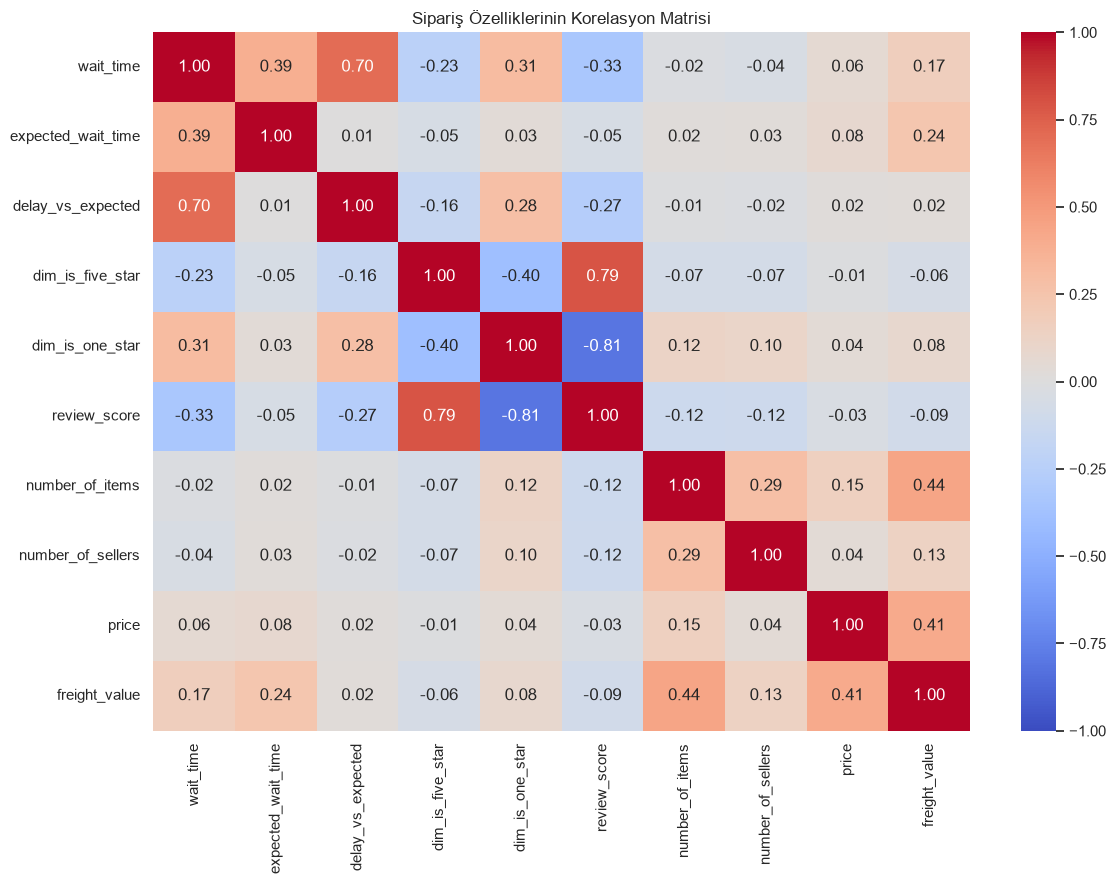

In [9]:
plt.figure(figsize=(12, 9))

sns.heatmap(
    orders.corr(numeric_only=True),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Sipariş Özelliklerinin Korelasyon Matrisi")
plt.tight_layout()
plt.show()

## 1 - Tek Değişkenli Regresyon

❓ [statsmodels](https://www.statsmodels.org/stable/generated/statsmodels.formula.api.ols.html) ile `statsmodels.formula.api` kullanarak hızlı bir şekilde şunları oluşturun:
 - `model1`: `review_score`'un `wait_time` üzerinde ols regresyonu
 - `model2`: `review_score`'un `delay_vs_expected` üzerinde ols regresyonu

Her biri için `summary` tablosunu yazdırın ve sonuçları yorumlayin:
- Bu sonuçların seaborn regplot sonuçları ile nasıl eşleştiğini anladığınızdan emin olun
- Regresyon performans metriği `R-squared`, `individual regression coefficients`, `t-values`, `p-values` ve `95% confidence intervals`'ı okuyun

***Model 1***:

In [10]:
model1 = smf.ols(
    "review_score ~ wait_time",
    data=orders
).fit()

print(model1.summary())

                            OLS Regression Results                            
Dep. Variable:           review_score   R-squared:                       0.111
Model:                            OLS   Adj. R-squared:                  0.111
Method:                 Least Squares   F-statistic:                 1.208e+04
Date:                Tue, 27 Oct 2026   Prob (F-statistic):               0.00
Time:                        20:00:56   Log-Likelihood:            -1.5519e+05
No. Observations:               96353   AIC:                         3.104e+05
Df Residuals:                   96351   BIC:                         3.104e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      4.7236      0.006    729.482      0.0

***Model 2***:

In [11]:
model2 = smf.ols(
    "review_score ~ delay_vs_expected",
    data=orders
).fit()

print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:           review_score   R-squared:                       0.074
Model:                            OLS   Adj. R-squared:                  0.074
Method:                 Least Squares   F-statistic:                     7715.
Date:                Tue, 27 Oct 2026   Prob (F-statistic):               0.00
Time:                        20:01:07   Log-Likelihood:            -1.5717e+05
No. Observations:               96353   AIC:                         3.143e+05
Df Residuals:                   96351   BIC:                         3.144e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             4.2124      0.00

## 2 - Çok Değişkenli Regresyon

❓ Siparişe bir gün `delay_vs_expected` eklemenin `review_score` üzerindeki etkisi nedir, **`wait_time` sabit tutarak**? İki özellikten hangisi düşük `review_score` için en açıklayıcıdır?

Bu amaçla, `wait_time` ve `delay_vs_expected`'in özellikler (bağımsız değişkenler) olduğu ve `review_score`'un hedef (bağımlı değişken) olduğu bir OLS modeli `model3`'ü çalıştırın

***Model 3***:

In [12]:
model3 = smf.ols(
    "review_score ~ wait_time + delay_vs_expected",
    data=orders
).fit()

print(model3.summary())

karsilastirma = pd.DataFrame({
    "tek_degiskenli_katsayi": [
        model1.params["wait_time"],
        model2.params["delay_vs_expected"]
    ],
    "cok_degiskenli_katsayi": [
        model3.params["wait_time"],
        model3.params["delay_vs_expected"]
    ],
    "cok_degiskenli_p": [
        model3.pvalues["wait_time"],
        model3.pvalues["delay_vs_expected"]
    ]
}, index=["wait_time", "delay_vs_expected"])

display(karsilastirma)

for degisken, digeri in [
    ("wait_time", "delay_vs_expected"),
    ("delay_vs_expected", "wait_time")
]:
    katsayi = model3.params[degisken]
    alt, ust = model3.conf_int().loc[degisken]

    print(
        f"{digeri} sabitken {degisken} için bir günlük artış, "
        f"tahmin edilen ortalama puanda {katsayi:.4f} "
        f"puanlık değişimle ilişkilidir."
    )
    print(
        f"%95 güven aralığı: [{alt:.4f}, {ust:.4f}] | "
        f"p = {model3.pvalues[degisken]:.3g}\n"
    )

print(
    f"Model 3, puan varyasyonunun "
    f"%{model3.rsquared * 100:.2f} kadarını açıklıyor."
)

                            OLS Regression Results                            
Dep. Variable:           review_score   R-squared:                       0.114
Model:                            OLS   Adj. R-squared:                  0.114
Method:                 Least Squares   F-statistic:                     6211.
Date:                Tue, 27 Oct 2026   Prob (F-statistic):               0.00
Time:                        20:01:18   Log-Likelihood:            -1.5504e+05
No. Observations:               96353   AIC:                         3.101e+05
Df Residuals:                   96350   BIC:                         3.101e+05
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             4.6500      0.00

,tek_degiskenli_katsayi,cok_degiskenli_katsayi,cok_degiskenli_p
wait_time,-0.045349,-0.038232,0.000000e+00
delay_vs_expected,-0.075137,-0.020565,2.381195e-68


delay_vs_expected sabitken wait_time için bir günlük artış, tahmin edilen ortalama puanda -0.0382 puanlık değişimle ilişkilidir.
%95 güven aralığı: [-0.0394, -0.0371] | p = 0

wait_time sabitken delay_vs_expected için bir günlük artış, tahmin edilen ortalama puanda -0.0206 puanlık değişimle ilişkilidir.
%95 güven aralığı: [-0.0229, -0.0183] | p = 2.38e-68

Model 3, puan varyasyonunun %11.42 kadarını açıklıyor.


### Tek ve çok değişkenli modellerin karşılaştırılması

Tek değişkenli modeller her teslimat değişkeninin puanla ilişkisini
ayrı ayrı inceler. Çok değişkenli model ise bir değişkenin
katsayısını, diğer değişken sabitken yorumlamamızı sağlar.

Bekleme süresi ve gecikme birbiriyle ilişkili olduğu için,
iki değişken aynı modele alındığında katsayılar değişebilir.
Bunlar kısmi regresyon katsayılarıdır; korelasyon katsayıları değildir.

İki değişken de gün cinsinden ölçüldüğünden katsayıların mutlak
değerleri bir günlük değişim açısından karşılaştırılabilir.
Ancak yalnızca katsayı büyüklüğü, genel değişken önemini belirlemez.

Küçük p-değeri ilişkinin istatistiksel anlamlılığıyla ilgilidir;
büyük etki veya yüksek tahmin başarısı anlamına gelmez.
Bu gözlemsel analiz, nedensellik kanıtlamaz.

----
👉 Çok değişkenli regresyon, bir özelliğin etkisini izole etmek ve diğer özelliklerin etkisini kontrol etmek için bize izin verir. Bu yeni katsayılara **`kısmi korelasyon katsayıları`** denir. 

❓ Yukarıda *seaborn* ile hesaplanan **basit regresyon** katsayıları ile fark görebilir misiniz? 

❓ `wait_time` ve `delay_vs_expected` için göreceli eğimler hakkında ne söyleyebilirsiniz?

<details>
    <summary>- 💡 Solution 💡-</summary>

- Holding `wait_time` constant, each additional day of `delay` reduces the review_score on average by 0.0205 [0.023 - 0.018] points
- Holding `delay` constant, each additional day of `wait_time` reduces the review_score on average by 0.0383 [0.039 - 0.037] points

Contrary to what was found with the simple bivariate correlation analysis, `delay` is actually less impactful than `wait_time` in driving lower `review_score`! This interesting finding demonstrates the importance of multi-variate regression to remove the potential impact of confounding factors

---
❌ R-squared oldukça düşük: review_score varyasyonlarının en fazla %12'si `wait_time` ve `delay_vs_expected`'in birleşik varyasyonları tarafından açıklanır.

✅ Doğrusal regresyonun açıklanabilirliğini iyileştirmek için regresyonumuza daha fazla özellik eklemeyi deneyelim.

Sonraki adımlarda `orders` veri setinden daha fazla özellik içeren yeni bir OLS `model4` oluşturacağız. Adım adım size rehberlik edeceğiz.

📝 <u>Not</u>: bir **`Çok Değişkenli Doğrusal Regresyon`** aynı zamanda **`Ordinary Least Squares`** yöntemi olarak da adlandırılır çünkü bu modelde **`MSE Ortalama Kare Hatalar`**'ı minimize etmek istiyoruz

***Model 4***:

❓ Hangi özellikleri göz önünde almak istersiniz?

👉 Bu özelliklerle bir `features` DataFrame oluşturun.

- ⚠️ **veri sızıntısı** oluşturmayın: `review_score`'tan doğrudan türetilen özellikleri eklemeyin
- ⚠️ Birbirleriyle mükemmel bir şekilde ilişkili olan iki özellik eklemeyin

In [13]:
feature_columns = [
    "wait_time",
    "delay_vs_expected",
    "number_of_items",
    "number_of_sellers",
    "price",
    "freight_value"
]

features = orders[feature_columns].copy()

display(features.head())
display(features.corr())

,wait_time,delay_vs_expected,number_of_items,number_of_sellers,price,freight_value
0,8.436574,0.0,1,1,29.99,8.72
1,13.782037,0.0,1,1,118.70,22.76
2,9.394213,0.0,1,1,159.90,19.22
3,13.208750,0.0,1,1,45.00,27.20
4,2.873877,0.0,1,1,19.90,8.72


,wait_time,delay_vs_expected,number_of_items,number_of_sellers,price,freight_value
wait_time,1.000000,0.702802,-0.019855,-0.040807,0.055169,0.167226
delay_vs_expected,0.702802,1.000000,-0.013711,-0.017212,0.016463,0.024152
number_of_items,-0.019855,-0.013711,1.000000,0.288560,0.153561,0.438307
number_of_sellers,-0.040807,-0.017212,0.288560,1.000000,0.043845,0.133658
price,0.055169,0.016463,0.153561,0.043845,1.000000,0.410038
freight_value,0.167226,0.024152,0.438307,0.133658,0.410038,1.000000


Sonra, özellikleri "standardize" edeceğiz.

**Bu ne anlama gelir?**

⚖️  Her özellik $X_i$'yi ilgili z-score'una $Z_i = \frac{X_i - \mu_i}{\sigma_i}$ dönüştüreceğiz.

**Neden?**

Bir `çok değişkenli doğrusal regresyon`'da, her özelliğin hedef üzerindeki etkisini ölçmeye çalışıyoruz.
    
⚠️ Ölçek etkileri nedeniyle, bazı özellikler yanlışlıkla diğerlerinden daha önemli olarak görülecektir
    
> Örneğin: "yatak odası sayısı" özelliği 1 ile 5 arasında ve "yüzey" özelliği 20 ile 200 m² arasında ise, bu iki özelliğin aralıkları oldukça farklıdır...

Bu nedenle kısmi regresyon katsayıları $\beta_i$'yi birlikte karşılaştırabilmek için standardize ederiz. Aksi takdirde, $\beta_i$ aynı boyuta sahip olmayacak, yani elmalar (örn. "gün başına review-yıldızlar") ile portakalları (örn. "BRL başına review-yıldızlar") karşılaştırmış olacaksınız!

📅 Makine Öğrenmesi Algoritmalarını keşfettiğimizde, herhangi bir hedefi tahmin etmeye çalışmadan önce bazı ölçekleme işlemleri gerçekleştirmemiz gerekecektir.

👉  Özelliklerinizi standardize edin:

1. `features` DataFrame'inizden başlayın
1. `mean`'i çıkarın
1. Standart sapma `std`'ye bölün.
1. Sonucu `orders_standardized` değişkenine kaydedin.
1. Son olarak, `orders['review_score']` sütununu `orders_standardized`'e kopyalayın.

2. ve 3. adımları basit bir matematiksel işlem olarak yazabilirsiniz, hatta DataFrames ile de. Pandas bunu anlamak için yeterince akıllıdır.

<details>
  <summary><i>İpucu</i></summary>

  ```python
  features - features.mean() / features.std()
  ```

</details>

👉 `model4`'ü oluşturun ve eğitin.

In [14]:
orders_standardized = (
    features - features.mean()
) / features.std()

orders_standardized["review_score"] = orders["review_score"]

formula = "review_score ~ " + " + ".join(feature_columns)

model4 = smf.ols(
    formula,
    data=orders_standardized
).fit()

print(model4.summary())

                            OLS Regression Results                            
Dep. Variable:           review_score   R-squared:                       0.141
Model:                            OLS   Adj. R-squared:                  0.141
Method:                 Least Squares   F-statistic:                     2633.
Date:                Tue, 27 Oct 2026   Prob (F-statistic):               0.00
Time:                        20:02:08   Log-Likelihood:            -1.5356e+05
No. Observations:               96353   AIC:                         3.071e+05
Df Residuals:                   96346   BIC:                         3.072e+05
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             4.1557      0.00

---
❓ En önemli özellikler nelerdir? (onları iyi görselleştirmek için `.plot(kind='barh')` ile bir çubuk grafik yapın)
- Genel regresyon performansı nasıl değişti?
- Bu regresyon istatistiksel olarak anlamlı mıdır?

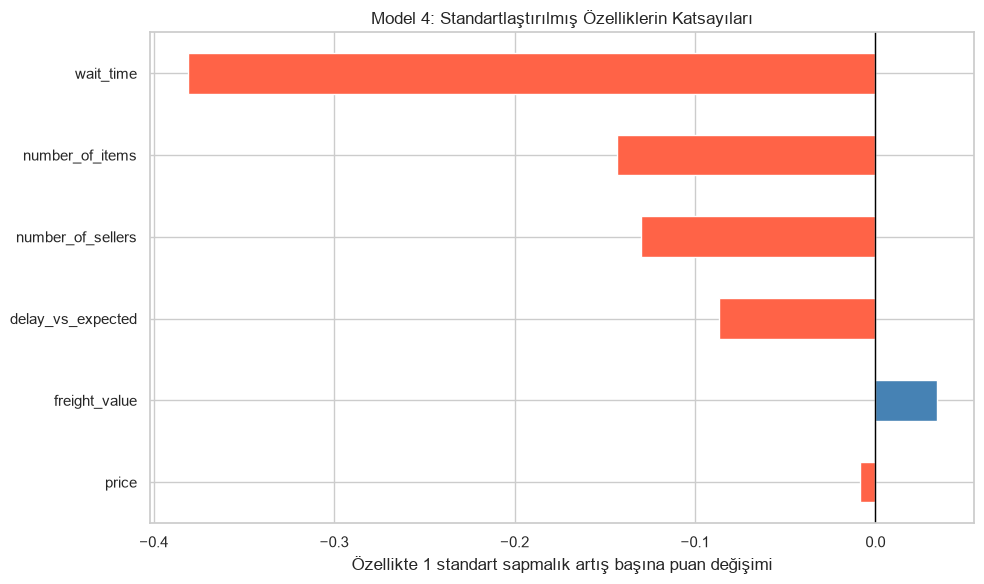

,katsayi,p_degeri,guven_alt,guven_ust
Intercept,4.155688,0.000000e+00,4.148167,4.163209
wait_time,-0.381184,0.000000e+00,-0.392096,-0.370271
delay_vs_expected,-0.086865,5.855470e-57,-0.097562,-0.076167
number_of_items,-0.143472,4.979880e-227,-0.152190,-0.134754
number_of_sellers,-0.130078,2.065789e-229,-0.137941,-0.122215
price,-0.008335,4.782071e-02,-0.016589,-0.000080
freight_value,0.033865,1.191544e-12,0.024526,0.043204


,model,R2,duzeltilmis_R2
0,Model 1,0.111395,0.111385
1,Model 2,0.074137,0.074127
2,Model 3,0.114205,0.114187
3,Model 4,0.140894,0.140840


En büyük mutlak standartlaştırılmış katsayı: wait_time
Model 4 genel F testi p-değeri: 0
Model 4 genel F testine göre: İstatistiksel olarak anlamlı


In [15]:
katsayilar = model4.params.drop("Intercept")

sirali = katsayilar.reindex(
    katsayilar.abs().sort_values().index
)

plt.figure(figsize=(10, 6))
sirali.plot(
    kind="barh",
    color=["tomato" if x < 0 else "steelblue" for x in sirali]
)
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Özellikte 1 standart sapmalık artış başına puan değişimi")
plt.title("Model 4: Standartlaştırılmış Özelliklerin Katsayıları")
plt.tight_layout()
plt.show()

guven = model4.conf_int()

katsayi_tablosu = pd.DataFrame({
    "katsayi": model4.params,
    "p_degeri": model4.pvalues,
    "guven_alt": guven[0],
    "guven_ust": guven[1]
})

display(katsayi_tablosu)

performans = pd.DataFrame({
    "model": ["Model 1", "Model 2", "Model 3", "Model 4"],
    "R2": [
        model1.rsquared, model2.rsquared,
        model3.rsquared, model4.rsquared
    ],
    "duzeltilmis_R2": [
        model1.rsquared_adj, model2.rsquared_adj,
        model3.rsquared_adj, model4.rsquared_adj
    ]
})

display(performans)

print("En büyük mutlak standartlaştırılmış katsayı:",
      katsayilar.abs().idxmax())
print(f"Model 4 genel F testi p-değeri: {model4.f_pvalue:.3g}")
print(
    "Model 4 genel F testine göre:",
    "İstatistiksel olarak anlamlı"
    if model4.f_pvalue < 0.05
    else "İstatistiksel olarak anlamlı değil"
)

### Model 4 yorumu

Özellikleri standartlaştırdığımız için katsayılar, ilgili özellikte
bir standart sapmalık artışla ilişkili puan değişimini gösterir.
Diğer model değişkenleri sabit tutulur. Hedef puan ölçeklenmemiştir.

Mutlak katsayı büyüklükleri ilişki gücünü karşılaştırmaya yardımcı
olur; ilişkili özellikler nedeniyle bunları kesin bir önem
sıralaması veya nedensel etki olarak değerlendirmemek gerekir.

Ek özelliklerle R² artabilir. Düzeltilmiş R², eklenen değişken
sayısını da dikkate alır. Buradaki değerler eğitim verisi üzerindeki
uyumu gösterir; yeni veride tahmin başarısı ayrıca ölçülmelidir.

Genel F testinin p-değeri 0.05'ten küçükse, tüm eğimlerin birlikte
sıfır olduğu hipotezi reddedilir. Bu, modelin mutlaka yüksek
açıklama gücüne sahip olduğu anlamına gelmez.

<details>
    <summary>- 💡 Açıklamalar 💡 -</summary>
    

- `wait_time` en büyük açıklayıcı değişkendir
- Tek bir sipariş için ne kadar çok `items` ve `sellers` varsa, `review_score` o kadar düşük görünür
- Mesafe de müşteri memnuniyetinde rol oynar.
- Özellik seçiminize bağlı olarak, `price` ve `freight_value` hakkında p-değerleri çok yüksekse hiçbir sonuca varamayabilirsiniz
    
- Genel olarak, bu çok değişkenli regresyon, F-istatistiği 1'den çok daha büyük olduğu için istatistiksel olarak anlamlı kalır (en az bir özelliğin çok düşük p-değeri vardır)

- R-squared çok fazla artmadı. `review_score`'un açıklanabilirliğinin çoğu orders veri seti dışında yer alır.

⚠️ Gözlem sayısı (n) özellik sayısından (p) çok daha yüksek olduğunda düşük R-squared yaygındır. Böyle regresyonlardan, istatistiksel olarak anlamlı olması koşuluyla yine de ilgili içgörüler elde edilebilir.
</details>



## 3 - Model Performansını Kontrol Edin

⚠️ Regresyon performansı sadece R-squared'i ile ölçülmemelidir!

👀 Her zaman tahminlerin dağılımını, özellikle de kalıntıları görselleştirin.

❓ Kalıntıları hesaplayın.

Kalıntıların ortalamasının 0'a eşit olduğunu görmelisiniz (doğrusal regresyon yapılırken bunu her zaman doğrulayın)

In [16]:
predicted_review_score = model4.fittedvalues
residuals = model4.resid

print(f"Kalıntıların ortalaması: {residuals.mean():.10f}")

display(pd.DataFrame({
    "gercek_puan": orders_standardized["review_score"],
    "tahmin": predicted_review_score,
    "kalinti": residuals
}).head())

Kalıntıların ortalaması: 0.0000000000


,gercek_puan,tahmin,kalinti
0,4,4.369260,-0.369260
1,4,4.172359,-0.172359
2,5,4.341983,0.658017
3,5,4.205422,0.794578
4,5,4.593877,0.406123


🧮 İlişkili RMSE'yi hesaplayın.

In [17]:
rmse = np.sqrt(np.mean(residuals ** 2))

print(f"Eğitim verisi RMSE: {rmse:.4f} puan")

Eğitim verisi RMSE: 1.1910 puan


📊 `residuals`'ı bir histogramda çizin.

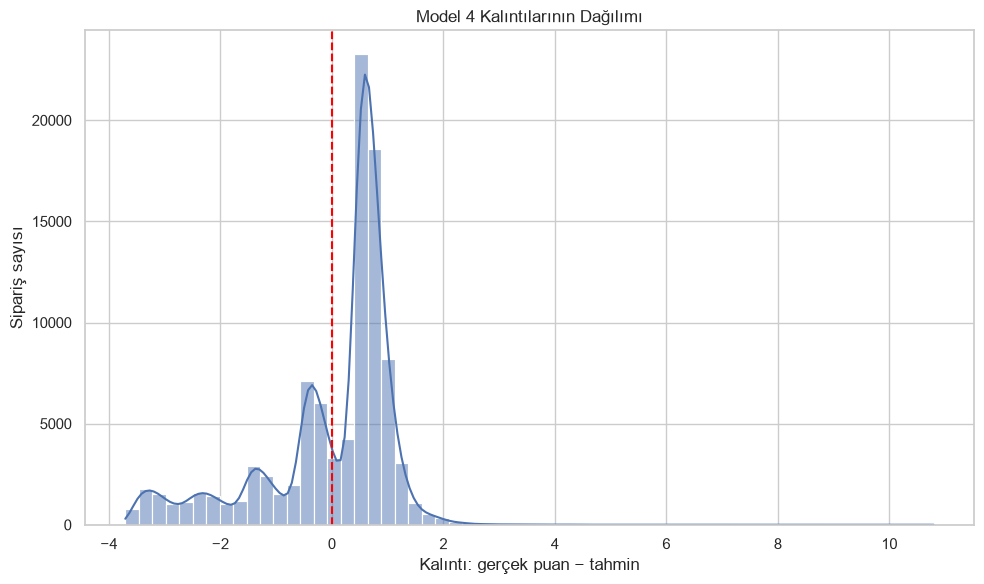

In [18]:
plt.figure(figsize=(10, 6))

sns.histplot(residuals, bins=60, kde=True)
plt.axvline(0, color="red", linestyle="--")

plt.xlabel("Kalıntı: gerçek puan − tahmin")
plt.ylabel("Sipariş sayısı")
plt.title("Model 4 Kalıntılarının Dağılımı")
plt.tight_layout()
plt.show()

❓ Kalıntıların distplot'unun neden bu kadar garip bir şekle sahip olduğunu tahmin edebilir misiniz?

*İpucu:*<br/>
👉 Aynı grafik üzerinde hem `review_score`'un dağılımını hem de `predicted_review_score`'un dağılımını çizin.

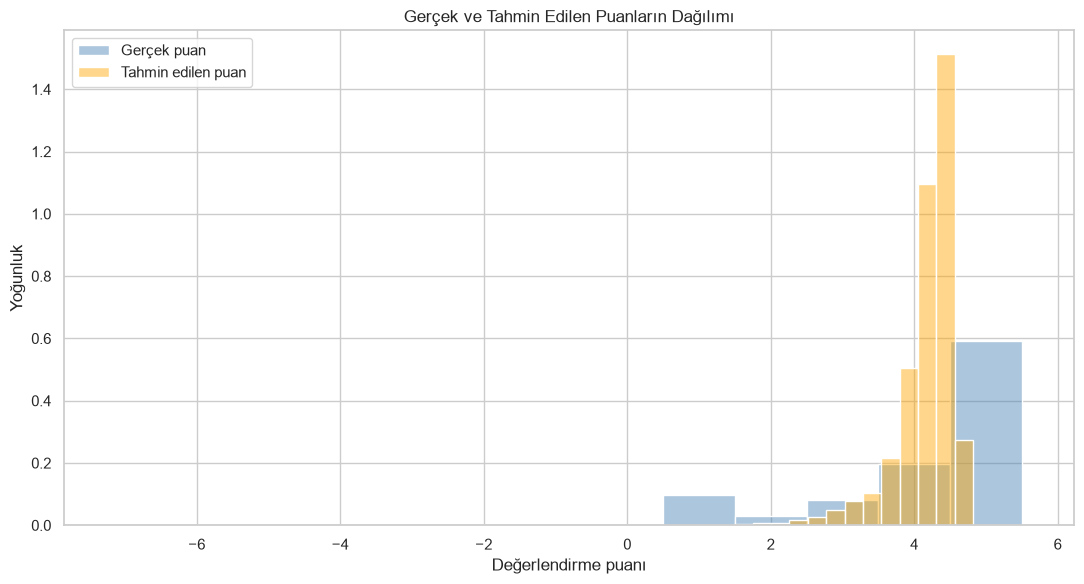

1–5 aralığı dışındaki tahminlerin oranı: %0.18


In [19]:
plt.figure(figsize=(11, 6))

sns.histplot(
    orders_standardized["review_score"],
    bins=np.arange(0.5, 6, 1),
    stat="density",
    color="steelblue",
    alpha=0.45,
    label="Gerçek puan"
)

sns.histplot(
    predicted_review_score,
    bins=50,
    stat="density",
    color="orange",
    alpha=0.45,
    label="Tahmin edilen puan"
)

plt.xlabel("Değerlendirme puanı")
plt.ylabel("Yoğunluk")
plt.title("Gerçek ve Tahmin Edilen Puanların Dağılımı")
plt.legend()
plt.tight_layout()
plt.show()

aralik_disi = (
    (predicted_review_score < 1) |
    (predicted_review_score > 5)
).mean()

print(f"1–5 aralığı dışındaki tahminlerin oranı: %{aralik_disi * 100:.2f}")

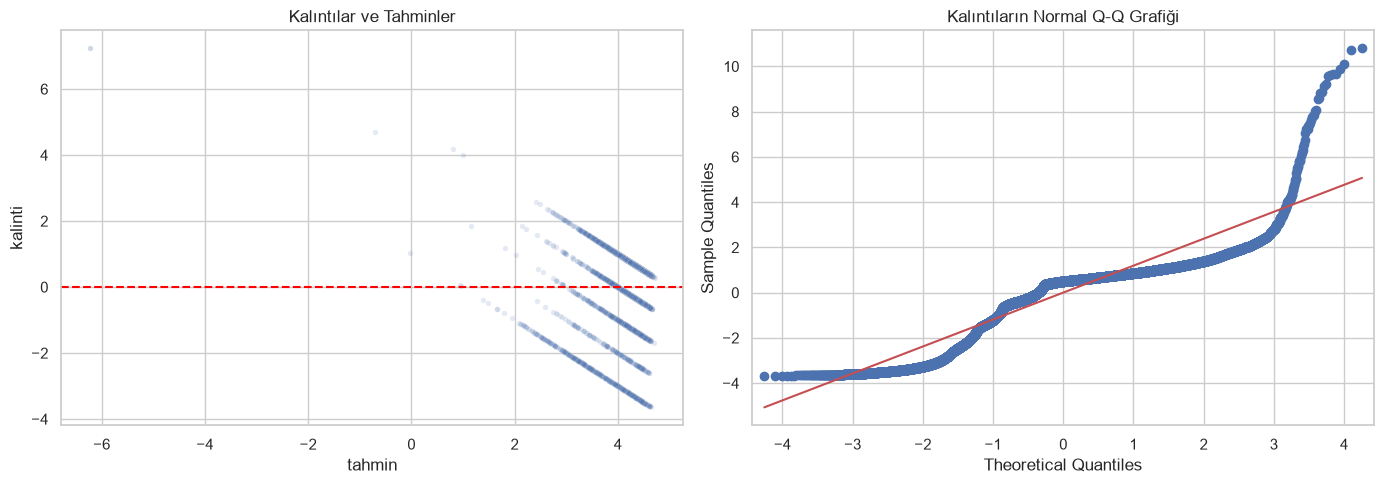

In [20]:
kontrol = pd.DataFrame({
    "tahmin": predicted_review_score,
    "kalinti": residuals
})

kontrol_ornek = kontrol.sample(
    n=min(5000, len(kontrol)),
    random_state=42
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=kontrol_ornek,
    x="tahmin",
    y="kalinti",
    alpha=0.15,
    s=15,
    ax=axes[0]
)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Kalıntılar ve Tahminler")

sm.qqplot(
    residuals,
    line="s",
    ax=axes[1]
)
axes[1].set_title("Kalıntıların Normal Q-Q Grafiği")

plt.tight_layout()
plt.show()

📈 Aslında, önceki zorlukta `review_score`'un `delay_vs_expected`'e karşı `regresyon çizgisi`'ni zaten çizmiştik.

Bu çizimi yeniden görselleştirmek için aşağıdaki hücreyi çalıştırın:

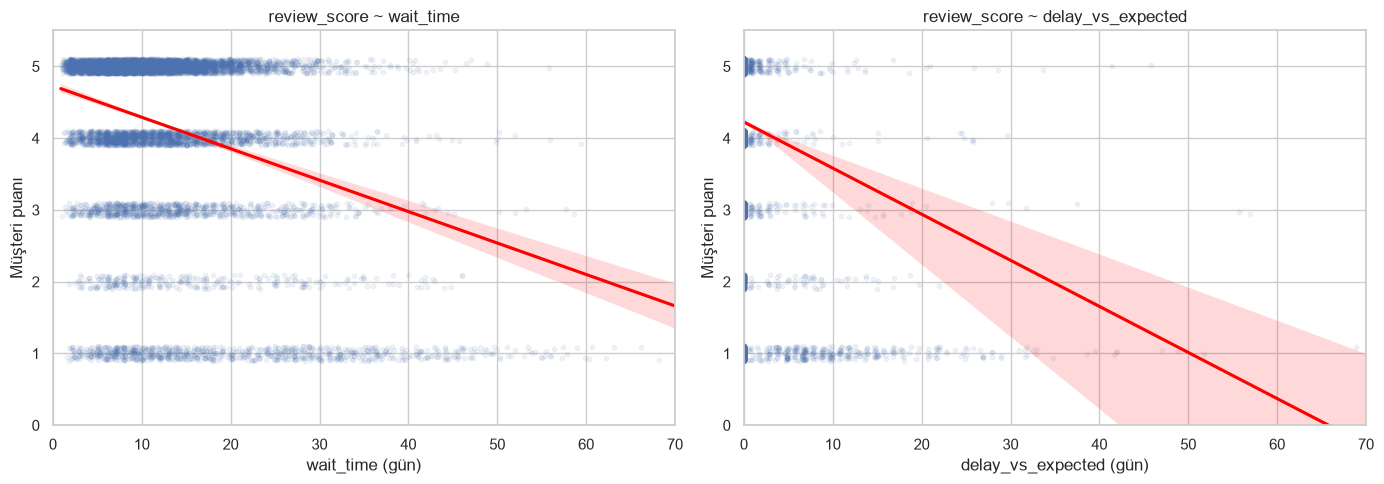

In [21]:
sample = orders.sample(
    n=min(10_000, len(orders)),
    random_state=42
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, degisken in zip(
    axes,
    ["wait_time", "delay_vs_expected"]
):
    sns.regplot(
        data=sample,
        x=degisken,
        y="review_score",
        y_jitter=0.1,
        ci=95,
        seed=42,
        scatter_kws={"alpha": 0.08, "s": 10},
        line_kws={"color": "red"},
        ax=ax
    )

    ax.set_xlim(0, 70)
    ax.set_ylim(0, 5.5)
    ax.set_xlabel(f"{degisken} (gün)")
    ax.set_ylabel("Müşteri puanı")
    ax.set_title(f"review_score ~ {degisken}")

plt.tight_layout()
plt.show()

### Sonuç ve modelin sınırlılıkları

- Tek değişkenli modeller teslimat süreleriyle müşteri puanı
  arasındaki ilişkileri ayrı ayrı gösterir. Çok değişkenli model,
  bir değişkenin katsayısını diğer değişken sabitken yorumlar.
- Katsayıların yönü, büyüklüğü, p-değerleri ve güven aralıkları
  birlikte değerlendirilmelidir. İstatistiksel anlamlılık,
  nedensellik veya yüksek tahmin başarısı değildir.
- Sabit terimli OLS modelinde eğitim kalıntılarının ortalamasının
  yaklaşık sıfır olması beklenir. Bu tek başına iyi uyum kanıtı değildir.
- Gerçek puanlar yalnızca 1, 2, 3, 4 ve 5 olabilirken model sürekli
  tahmin üretir. Kalıntı grafiğinde bu nedenle şeritler oluşabilir;
  şeritler tek başına değişen varyans kanıtı değildir.
- Kalıntıların yayılımı tahminlerle değişiyorsa sabit varyans
  varsayımı sorgulanmalıdır. Q-Q grafiğindeki sapmalar da normal
  hata varsayımının uygunluğunu değerlendirmeye yardımcı olur.
- Değişen varyans varsa HC3 gibi sağlam standart hatalarla
  istatistiksel çıkarımların duyarlılığı kontrol edilebilir.
- R² ve RMSE burada eğitim verisinde hesaplanmıştır. Yeni
  siparişlerdeki başarının ölçülmesi için ayrı test verisi veya
  çapraz doğrulama gerekir.
- Puanlar sıralı ve sınırlıdır. Alternatif olarak ordinal lojistik
  regresyon düşünülebilir. Çok sınıflı sınıflandırma modelleri de
  denenebilir; ancak sınıfların sıralı yapısını ayrıca dikkate almak gerekir.
- Ürün kategorisi, bölge ve hizmet kalitesi gibi dışarıda kalan
  değişkenler sonuçlarla ilişkili olabilir. Bu yüzden teslimat
  süresinin tek başına puan düşüşüne neden olduğu söylenemez.

☝️ Bir siparişin `review_score`'unu onun `wait_time` veya `delay_vs_expected`'ine karşı regrese etmenin zor olduğunu görebilirsiniz çünkü `review_score` ayrı bir sayı olup aynı zamanda bir kategori olarak da yorumlanabilir: 1 (çok kötü), 2 (kötü), 3 (orta), 4 (iyi), 5 (mükemmel).

📅 Sonraki ünitede, adına rağmen bir `Classification Algorithm` olan yeni bir model keşfedeceksiniz: `Logistic Regression` 

☝️ Sonuç olarak, modelimiz iki nedenden dolayı o kadar harika değil:
- İlk olarak, review_scores'un önemli bir kısmını açıklamak için yeterli özelliğimiz olmadığı için (düşük R-squared)
- İkinci olarak, "doğrusal regresyon" işlevini ayrı bir sınıflandırma problemine uydurmaya çalıştığımız için

💡 Bireysel siparişler üzerinde çalışmak ve `wait_time` tabanlı ayrı `review_score`'ları açıklamaya çalışmak yerine, bir sonraki zorlukta siparişleri satıcılar tarafından toplayarak analiz edilmesini satıcı seviyesine yoğunlaştıracağız.

🏁 Harika iş!

💾 İşiniz bittiğinde bu not defterini *kaydetmeyi*, *commit* ve *push* etmeyi unutmayın!